<a href="https://colab.research.google.com/github/SachiniKalansooriya/Dengue_Ensemble_Forecasting/blob/main/Dengue_Ensemble_Forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install pyreadr xgboost lightgbm catboost statsmodels shap streamlit joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 8.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 41.8 MB/s  0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 63.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 41.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [streamlit]


In [ ]:
import os, pyreadr, urllib.request
os.makedirs("data", exist_ok=True)
url = "https://raw.githubusercontent.com/thiyangt/denguedatahub/master/data/srilanka_weekly_data.rda"
urllib.request.urlretrieve(url, "srilanka_weekly_data.rda")
dengue = list(pyreadr.read_r("srilanka_weekly_data.rda").values())[0]
dengue.to_csv("data/dengue_weekly.csv", index=False)

In [ ]:
import pandas as pd

In [ ]:
districts = {
    "Ampara": (7.30, 81.67), "Anuradhapura": (8.31, 80.40), "Badulla": (6.99, 81.06),
    "Batticaloa": (7.73, 81.69), "Colombo": (6.93, 79.85), "Galle": (6.05, 80.22),
    "Gampaha": (7.09, 79.99), "Hambanthota": (6.12, 81.12), "Jaffna": (9.66, 80.01),
    "Kalmune": (7.41, 81.83), "Kalutara": (6.58, 79.96), "Kandy": (7.29, 80.63),
    "Kegalle": (7.25, 80.35), "Kilinochchi": (9.39, 80.40), "Kurunegala": (7.49, 80.36),
    "Mannar": (8.98, 79.90), "Matale": (7.47, 80.62), "Matara": (5.95, 80.54),
    "Monaragala": (6.87, 81.35), "Mullaitivu": (9.27, 80.81), "NuwaraEliya": (6.97, 80.78),
    "Polonnaruwa": (7.94, 81.00), "Puttalam": (8.04, 79.83), "Ratnapura": (6.68, 80.40),
    "Trincomalee": (8.59, 81.21), "Vavuniya": (8.75, 80.50),
}

In [ ]:
print(len(districts), "districts")

26 districts


In [ ]:
import os, time, requests
from datetime import date, timedelta

os.makedirs("data/weather_raw", exist_ok=True)
end = (date.today() - timedelta(days=7)).isoformat()   # archive data lags a few days

for name, (lat, lon) in districts.items():
    path = f"data/weather_raw/{name}.csv"
    if os.path.exists(path):
        continue                                          # already downloaded
    params = {
        "latitude": lat, "longitude": lon,
        "start_date": "2006-12-01", "end_date": end,
        "daily": "precipitation_sum,temperature_2m_mean,relative_humidity_2m_mean",
        "timezone": "Asia/Colombo",
    }
    for attempt in range(5):
        r = requests.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=60)
        if r.status_code == 200:
            daily = pd.DataFrame(r.json()["daily"])
            daily["district"] = name
            daily.to_csv(path, index=False)
            print("done:", name, len(daily), "days")
            break
        print(name, "error", r.status_code, "- waiting 60 s")
        time.sleep(60)
    time.sleep(20)

done: Ampara 7290 days
done: Anuradhapura 7290 days
done: Badulla 7290 days
done: Batticaloa 7290 days
done: Colombo 7290 days
done: Galle 7290 days
done: Gampaha 7290 days
done: Hambanthota 7290 days
done: Jaffna 7290 days
done: Kalmune 7290 days
done: Kalutara 7290 days
done: Kandy 7290 days
done: Kegalle 7290 days
done: Kilinochchi 7290 days
done: Kurunegala 7290 days
done: Mannar 7290 days
done: Matale 7290 days
done: Matara 7290 days
done: Monaragala 7290 days
done: Mullaitivu 7290 days
done: NuwaraEliya 7290 days
done: Polonnaruwa 7290 days
done: Puttalam 7290 days
done: Ratnapura 7290 days
done: Trincomalee 7290 days
done: Vavuniya 7290 days


In [ ]:
import glob

weather = pd.concat([pd.read_csv(f) for f in glob.glob("data/weather_raw/*.csv")])
weather["time"] = pd.to_datetime(weather["time"])

def parse_dates(col):
    us_format  = pd.to_datetime(col, format="%m/%d/%Y", errors="coerce")
    iso_format = pd.to_datetime(col, format="%Y-%m-%d", errors="coerce")
    return us_format.fillna(iso_format)

dengue["start"] = parse_dates(dengue["start.date"])
dengue["end"]   = parse_dates(dengue["end.date"])
print("Dates that could not be read:", dengue["start"].isna().sum())

# give every day the start date of the dengue week it belongs to
weeks = dengue[["start", "end"]].drop_duplicates().sort_values("start")
weather = pd.merge_asof(weather.sort_values("time"), weeks,
                        left_on="time", right_on="start", direction="backward")
weather = weather[weather["time"] <= weather["end"]]

weekly = (weather.groupby(["district", "start"])
          .agg(rain_mm=("precipitation_sum", "sum"),
               temp_c=("temperature_2m_mean", "mean"),
               humidity=("relative_humidity_2m_mean", "mean"))
          .reset_index())
weekly.to_csv("data/weather_weekly.csv", index=False)

data = dengue.merge(weekly, on=["district", "start"], how="left")
data.to_csv("data/dengue_weather.csv", index=False)
print(data.shape)
print(data[["rain_mm", "temp_c", "humidity"]].isna().mean())
data.head()

Dates that could not be read: 0
(26753, 11)
rain_mm     0.0
temp_c      0.0
humidity    0.0
dtype: float64


,year,week,start.date,end.date,district,cases,start,end,rain_mm,temp_c,humidity
0,2006.0,52.0,12/23/2006,12/29/2006,Colombo,71.0,2006-12-23,2006-12-29,1.4,25.885714,74.571429
1,2006.0,52.0,12/23/2006,12/29/2006,Gampaha,12.0,2006-12-23,2006-12-29,1.4,25.828571,73.857143
2,2006.0,52.0,12/23/2006,12/29/2006,Kalutara,12.0,2006-12-23,2006-12-29,8.6,25.828571,80.428571
3,2006.0,52.0,12/23/2006,12/29/2006,Kandy,20.0,2006-12-23,2006-12-29,9.5,21.571429,85.000000
4,2006.0,52.0,12/23/2006,12/29/2006,Matale,4.0,2006-12-23,2006-12-29,5.1,23.271429,84.000000


## Exploratory Data Analysis

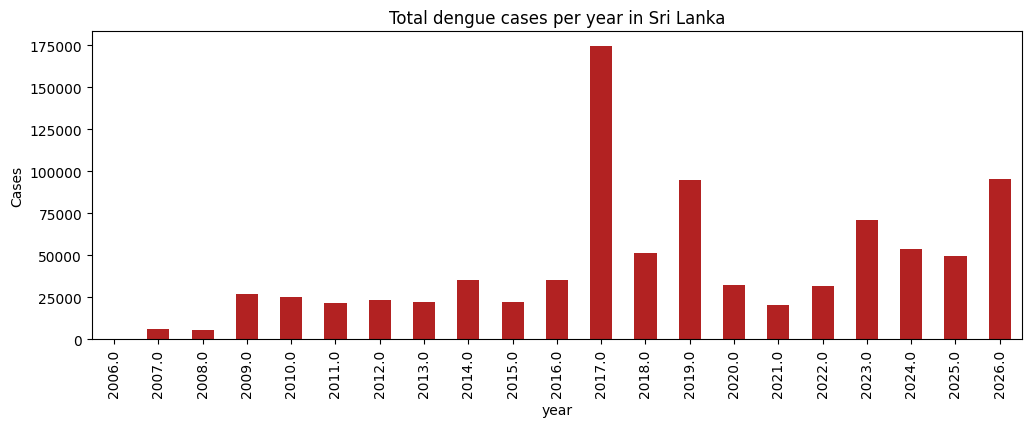

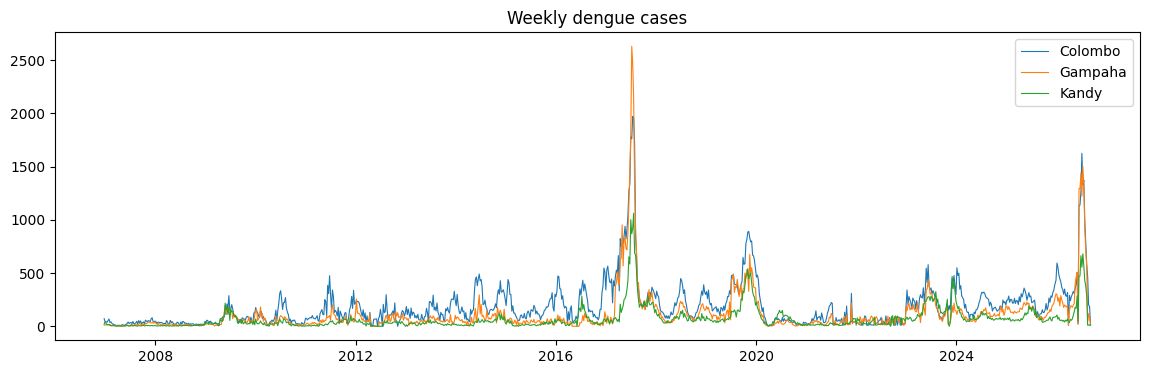

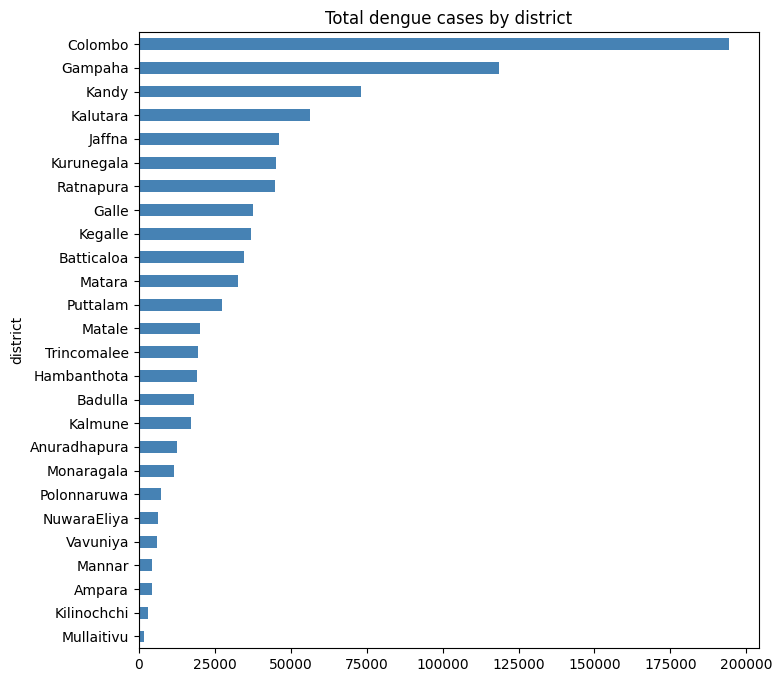

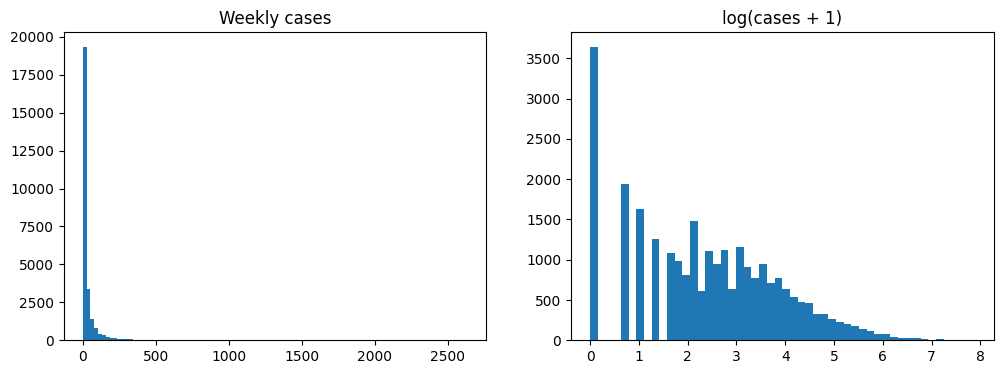

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

data = data.sort_values(["district", "start"]).reset_index(drop=True)

# 1. Total cases per year
data.groupby("year")["cases"].sum().plot(kind="bar", figsize=(12, 4), color="firebrick")
plt.title("Total dengue cases per year in Sri Lanka"); plt.ylabel("Cases"); plt.show()

# 2. Weekly cases for three districts
fig, ax = plt.subplots(figsize=(14, 4))
for d in ["Colombo", "Gampaha", "Kandy"]:
    s = data[data["district"] == d]
    ax.plot(s["start"], s["cases"], label=d, linewidth=0.8)
ax.set_title("Weekly dengue cases"); ax.legend(); plt.show()

# 3. Total cases by district
data.groupby("district")["cases"].sum().sort_values().plot(kind="barh", figsize=(8, 8), color="steelblue")
plt.title("Total dengue cases by district"); plt.show()

# 4. Distribution of weekly cases
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(data["cases"], bins=100); axes[0].set_title("Weekly cases")
axes[1].hist(np.log1p(data["cases"]), bins=50); axes[1].set_title("log(cases + 1)")
plt.show()

## Each model is trained on the training data (2008–2021) and evaluated on the test data (2022–2026).

Chart 1: Total cases per year

2017 was by far the worst year, with about 175,000 cases, more than 1.8 times any other year. The next highest years are 2019 and 2026 (about 95,000 each), followed by 2023 (about 71,000). The 2006 bar is almost empty because the data starts in late December 2006, and 2026 only includes data up to September, so the real 2026 total will be higher. Cases were low from 2020 to 2022 and have risen again since 2023. This shows that dengue varies greatly from year to year.

Chart 2: Weekly dengue cases

Colombo, Gampaha and Kandy rise and fall at the same times, so outbreaks affect these districts together. The largest weekly spike was in Gampaha during the 2017 outbreak, at about 2,600 cases in one week, while Colombo reached about 2,000. Other clear outbreaks appear in 2019 and 2026, where Colombo reached about 1,600 cases in one week. Between outbreaks there are several smaller rises every year. Outbreak weeks are many times higher than normal weeks, so they will be the hardest weeks for the models to predict.

Chart 3: Total cases by district

Colombo has the most cases (about 195,000), followed by Gampaha (about 120,000), Kandy (about 73,000) and Kalutara (about 56,000). Jaffna is fifth (about 46,000), so dengue is also a problem in the north, not only in the Western Province. The fewest cases are in Mullaitivu, Kilinochchi, Ampara and Mannar, each with less than about 5,000. The most affected districts are mostly large, densely populated and urban. Because case levels differ so much between districts, the district is used as an input feature.

Chart 4: Distribution of weekly cases

The left histogram shows that almost all weeks have low case counts: the first bar alone holds about 19,500 of the roughly 26,700 district-weeks, while a few outbreak weeks reach over 2,500 cases. This means the data is strongly right-skewed. After applying log(cases + 1) (right), the values are spread more evenly between 0 and about 8. The separate bar at 0 shows about 3,600 weeks with zero cases, mainly in small districts. We predict log(cases + 1) so a few extreme outbreak weeks don't dominate model training.

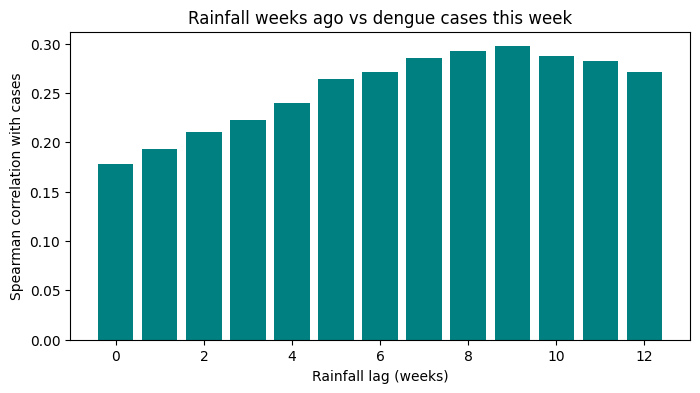

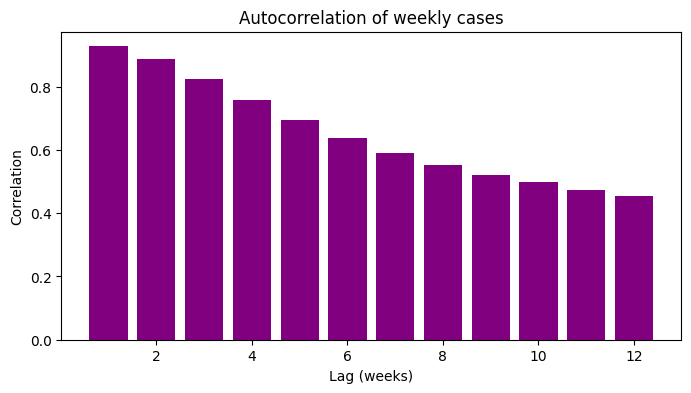

In [ ]:
corrs = []
for k in range(0, 13):
    rain_lag = data.groupby("district")["rain_mm"].shift(k)
    corrs.append(data["cases"].corr(rain_lag, method="spearman"))
plt.figure(figsize=(8, 4)); plt.bar(range(0, 13), corrs, color="teal")
plt.xlabel("Rainfall lag (weeks)"); plt.ylabel("Spearman correlation with cases")
plt.title("Rainfall weeks ago vs dengue cases this week"); plt.show()

# 6. How much does this week depend on last week?
ac = [data["cases"].corr(data.groupby("district")["cases"].shift(k)) for k in range(1, 13)]
plt.figure(figsize=(8, 4)); plt.bar(range(1, 13), ac, color="purple")
plt.xlabel("Lag (weeks)"); plt.ylabel("Correlation"); plt.title("Autocorrelation of weekly cases"); plt.show()

Chart 5: Rainfall weeks ago vs dengue cases

The correlation between rainfall and dengue cases is lowest for rainfall in the same week (about 0.18) and increases steadily with the lag. It is highest at a lag of 9 weeks (about 0.30), with 8 and 10 weeks almost as high, and then slowly falls. This matches the mosquito life cycle: rain creates breeding places, mosquitoes develop, the virus incubates, and cases are reported weeks later. The correlation is moderate, and part of it may come from both rainfall and dengue following the monsoon seasons, so rainfall alone cannot predict dengue but adds useful information. We therefore use rainfall from 2 to 12 weeks earlier as features.

Chart 6: Autocorrelation of weekly cases

The correlation between this week's cases and last week's is very high, about 0.93. It decreases slowly: about 0.76 after 4 weeks, 0.55 after 8 weeks and 0.46 after 12 weeks. This means dengue cases change gradually and outbreaks build up over several weeks. Because of this, simply predicting "same as last week" will already be very accurate, and our ensemble models must beat this baseline to be useful.

## Reload merged data

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("data", exist_ok=True)
if not os.path.exists("data/dengue_weather.csv"):
    from google.colab import files
    uploaded = files.upload()
    os.rename(list(uploaded.keys())[0], "data/dengue_weather.csv")

data = pd.read_csv("data/dengue_weather.csv", parse_dates=["start", "end"])
print(data.shape, data["district"].nunique(), "districts")

Saving dengue_weather.csv to dengue_weather.csv
(26753, 11) 26 districts


## Data Quality Check

Comparing each week's district pattern with the previous week showed seven broken weeks: three where the district values are scrambled (2026-03-30, 2026-06-08, 2026-09-07) and four that are exact copies of the previous week (2012-01-21, 2021-12-18, 2025-02-08, 2026-06-22). We replace these with values interpolated from neighbouring weeks, and drop the final week because it cannot be interpolated.

In [6]:
scrambled  = pd.to_datetime(["2026-03-30", "2026-06-08", "2026-09-07"])                # district values mixed up
duplicates = pd.to_datetime(["2012-01-21", "2021-12-18", "2025-02-08", "2026-06-22"])  # exact copy of the week before
bad_weeks = scrambled.append(duplicates)
print("Rows affected:", data["start"].isin(bad_weeks).sum())

data = data.sort_values(["district", "start"]).reset_index(drop=True)
data.loc[data["start"].isin(bad_weeks), "cases"] = np.nan
data["cases"] = data.groupby("district")["cases"].transform(
    lambda s: s.interpolate(limit_area="inside"))            # fill from the weeks before and after
data = data.dropna(subset=["cases"]).reset_index(drop=True)  # the very last week can't be filled
data["cases"] = data["cases"].round()
print("Rows after cleaning:", len(data), "| last week:", data["start"].max().date())

Rows affected: 156
Rows after cleaning: 26727 | last week: 2026-08-31


## Feature Engineering

Chart 5 showed that rainfall is most strongly linked to dengue cases 8–9 weeks later, so we use weather from 2 to 12 weeks earlier. All features use only past weeks, so the model never sees information from the week it is predicting.

In [7]:
df = data.sort_values(["district", "start"]).reset_index(drop=True)
g = df.groupby("district")

# Past cases (only information available before the week we predict)
for k in [1, 2, 3, 4, 8, 52]:
    df[f"cases_lag{k}"] = g["cases"].shift(k)
df["cases_roll4"] = g["cases"].transform(lambda s: s.shift(1).rolling(4).mean())
df["cases_roll8"] = g["cases"].transform(lambda s: s.shift(1).rolling(8).mean())
df["cases_trend"] = df["cases_lag1"] - df["cases_lag2"]          # rising or falling?

# Weather from 2-12 weeks ago (Chart 5: strongest link at 8-9 weeks)
for k in [2, 4, 6, 8, 10, 12]:
    df[f"rain_lag{k}"]  = g["rain_mm"].shift(k)
    df[f"temp_lag{k}"]  = g["temp_c"].shift(k)
    df[f"humid_lag{k}"] = g["humidity"].shift(k)
df["rain_roll4"] = g["rain_mm"].transform(lambda s: s.shift(1).rolling(4).sum())

# Season: week 52 should sit next to week 1
df["week_sin"] = np.sin(2 * np.pi * df["week"] / 52)
df["week_cos"] = np.cos(2 * np.pi * df["week"] / 52)

# District as one-hot columns
df = pd.concat([df, pd.get_dummies(df["district"], prefix="d", dtype=int)], axis=1)

# Target: log(cases + 1) because counts are very skewed (Chart 4)
df["target"] = np.log1p(df["cases"])

df = df.dropna().reset_index(drop=True)
feature_cols = [c for c in df.columns if c.startswith(("cases_", "rain_", "temp_", "humid_", "week_", "d_"))]

# Time-based split: train on the past, test on the future
train = df[df["year"] <= 2021]
test  = df[df["year"] >= 2022]
X_train, y_train = train[feature_cols], train["target"]
X_test,  y_test  = test[feature_cols],  test["target"]

print(len(feature_cols), "features")
print("Train:", train["start"].min().date(), "to", train["start"].max().date(), len(train), "rows")
print("Test: ", test["start"].min().date(),  "to", test["start"].max().date(),  len(test),  "rows")
df.to_csv("data/features.csv", index=False)

58 features
Train: 2007-12-22 to 2021-12-25 19032 rows
Test:  2022-01-01 to 2026-08-31 6343 rows


## Model Training and Comparison

In [13]:
import joblib, json, os
from sklearn.ensemble import StackingRegressor, RandomForestRegressor
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

if "stack" not in globals():   # retrain only if the runtime was reset
    stack = StackingRegressor(
        estimators=[
            ("rf",   RandomForestRegressor(n_estimators=200, max_features=0.5, min_samples_leaf=3, n_jobs=-1, random_state=42)),
            ("xgb",  XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=5, subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1)),
            ("lgbm", LGBMRegressor(n_estimators=500, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=42, verbose=-1)),
            ("cat",  CatBoostRegressor(iterations=500, learning_rate=0.05, depth=6, random_seed=42, verbose=0)),
        ],
        final_estimator=RidgeCV(), cv=KFold(n_splits=5, shuffle=False))
    stack.fit(X_train, y_train)

os.makedirs("models", exist_ok=True)
joblib.dump(stack, "models/stacking_model.pkl", compress=("xz", 9))   # about 20 MB
print("Saved:", round(os.path.getsize("models/stacking_model.pkl") / 1e6, 1), "MB")

import xgboost, catboost
print("xgboost==" + xgboost.__version__)
print("catboost==" + catboost.__version__)

from google.colab import files
files.download("models/stacking_model.pkl")

Saved: 19.8 MB
xgboost==3.4.1
catboost==1.2.10


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import time
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

y_true = test["cases"].values
naive_pred = test["cases_lag1"].values                      # "same as last week"
naive_rmse = np.sqrt(mean_squared_error(y_true, naive_pred))
outbreak = y_true >= np.quantile(y_true, 0.90)              # top 10% busiest weeks

results, predictions = [], {}

def evaluate(name, family, pred_cases, train_seconds=0.0):
    pred_cases = np.clip(pred_cases, 0, None)
    rmse = np.sqrt(mean_squared_error(y_true, pred_cases))
    results.append({
        "Model": name, "Type": family,
        "RMSE": round(rmse, 2),
        "MAE": round(mean_absolute_error(y_true, pred_cases), 2),
        "R2": round(r2_score(y_true, pred_cases), 3),
        "Skill vs baseline": round(1 - rmse / naive_rmse, 3),
        "Outbreak-week MAE": round(mean_absolute_error(y_true[outbreak], pred_cases[outbreak]), 1),
        "Train time (s)": round(train_seconds, 1),
    })
    predictions[name] = pred_cases
    print(f"{name:32s} RMSE={rmse:7.2f}  R2={r2_score(y_true, pred_cases):.3f}")

def fit_and_evaluate(name, family, model):
    t0 = time.time()
    model.fit(X_train, y_train)
    secs = time.time() - t0
    evaluate(name, family, np.expm1(model.predict(X_test)), secs)   # back from log scale
    return model

evaluate("Same as last week", "Baseline", naive_pred)

Same as last week                RMSE=  32.50  R2=0.888


In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, BaggingRegressor

dt = fit_and_evaluate("Decision Tree", "Single model",
        DecisionTreeRegressor(max_depth=8, min_samples_leaf=20, random_state=42))
rf = fit_and_evaluate("Random Forest", "Bagging",
        RandomForestRegressor(n_estimators=300, max_features=0.5, min_samples_leaf=3, n_jobs=-1, random_state=42))
bag = fit_and_evaluate("Bagged Decision Trees", "Bagging",
        BaggingRegressor(DecisionTreeRegressor(min_samples_leaf=3), n_estimators=100, n_jobs=-1, random_state=42))

Decision Tree                    RMSE=  35.78  R2=0.864
Random Forest                    RMSE=  32.36  R2=0.889
Bagged Decision Trees            RMSE=  32.88  R2=0.885


In [ ]:
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

gbm = fit_and_evaluate("Gradient Boosting (sklearn)", "Boosting",
        GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, random_state=42))
xgb = fit_and_evaluate("XGBoost", "Boosting",
        XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=5, subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1))
lgbm = fit_and_evaluate("LightGBM", "Boosting",
        LGBMRegressor(n_estimators=500, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=42, verbose=-1))
cat = fit_and_evaluate("CatBoost", "Boosting",
        CatBoostRegressor(iterations=500, learning_rate=0.05, depth=6, random_seed=42, verbose=0))

Gradient Boosting (sklearn)      RMSE=  29.94  R2=0.905
XGBoost                          RMSE=  32.14  R2=0.890
LightGBM                         RMSE=  30.27  R2=0.903
CatBoost                         RMSE=  30.02  R2=0.904


In [ ]:
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold

stack = fit_and_evaluate("Stacking (RF+XGB+LGBM+CatBoost)", "Stacking",
        StackingRegressor(
            estimators=[
                ("rf",   RandomForestRegressor(n_estimators=200, max_features=0.5, min_samples_leaf=3, n_jobs=-1, random_state=42)),
                ("xgb",  XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=5, subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1)),
                ("lgbm", LGBMRegressor(n_estimators=500, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=42, verbose=-1)),
                ("cat",  CatBoostRegressor(iterations=500, learning_rate=0.05, depth=6, random_seed=42, verbose=0)),
            ],
            final_estimator=RidgeCV(),                 # meta-model that combines the 4 models
            cv=KFold(n_splits=5, shuffle=False)))
print("Meta-model weights:", dict(zip(["RF", "XGB", "LGBM", "CatBoost"], stack.final_estimator_.coef_.round(3))))

Stacking (RF+XGB+LGBM+CatBoost)  RMSE=  29.50  R2=0.908
Meta-model weights: {'RF': np.float64(0.014), 'XGB': np.float64(0.146), 'LGBM': np.float64(0.417), 'CatBoost': np.float64(0.436)}


In [ ]:
results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
results_df

,Model,Type,RMSE,MAE,R2,Skill vs baseline,Outbreak-week MAE,Train time (s)
0,Stacking (RF+XGB+LGBM+CatBoost),Stacking,29.50,13.04,0.908,0.092,51.4,327.0
1,Gradient Boosting (sklearn),Boosting,29.94,13.10,0.905,0.079,51.7,51.3
2,CatBoost,Boosting,30.02,13.27,0.904,0.076,53.8,7.8
3,LightGBM,Boosting,30.27,13.14,0.903,0.069,51.9,2.8
4,XGBoost,Boosting,32.14,13.57,0.890,0.011,55.5,6.2
5,Random Forest,Bagging,32.36,13.36,0.889,0.004,55.0,78.4
6,Same as last week,Baseline,32.50,14.02,0.888,0.000,52.4,0.0
7,Bagged Decision Trees,Bagging,32.88,13.50,0.885,-0.012,54.9,53.8
8,Decision Tree,Single model,35.78,14.68,0.864,-0.101,62.1,0.4


## Hybrid Model: Random Forest + ARIMA


In [ ]:
import warnings
from statsmodels.tsa.statespace.sarimax import SARIMAX
warnings.filterwarnings("ignore")

t0 = time.time()
arima_parts = []
for district, s in data.sort_values("start").groupby("district"):
    y = np.log1p(s.set_index("start")["cases"].astype(float))
    y_train_d = y[y.index.year <= 2021]
    model = SARIMAX(y_train_d.values, order=(2, 1, 1)).fit(disp=False)   # fitted on training years only
    full = model.apply(y.values)                      # same parameters, run over all weeks
    one_step = full.get_prediction().predicted_mean   # each week forecast using only earlier weeks
    arima_parts.append(pd.DataFrame({"district": district, "start": y.index, "arima_log": one_step}))
arima_df = pd.concat(arima_parts)
arima_secs = time.time() - t0

train = train.merge(arima_df, on=["district", "start"], how="left")
test  = test.merge(arima_df,  on=["district", "start"], how="left")

# ARIMA on its own
evaluate("ARIMA (2,1,1) per district", "Time series", np.expm1(test["arima_log"].values), arima_secs)

# Hybrid: RF learns what ARIMA gets wrong (the residual)
t0 = time.time()
resid_train = y_train.values - train["arima_log"].values
rf_resid = RandomForestRegressor(n_estimators=300, max_features=0.5, min_samples_leaf=3, n_jobs=-1, random_state=42)
rf_resid.fit(X_train, resid_train)
hybrid_log = test["arima_log"].values + rf_resid.predict(X_test)
evaluate("Hybrid RF + ARIMA", "Hybrid", np.expm1(hybrid_log), arima_secs + time.time() - t0)

ARIMA (2,1,1) per district       RMSE=  36.77  R2=0.856
Hybrid RF + ARIMA                RMSE=  31.79  R2=0.893


## Model Comparison

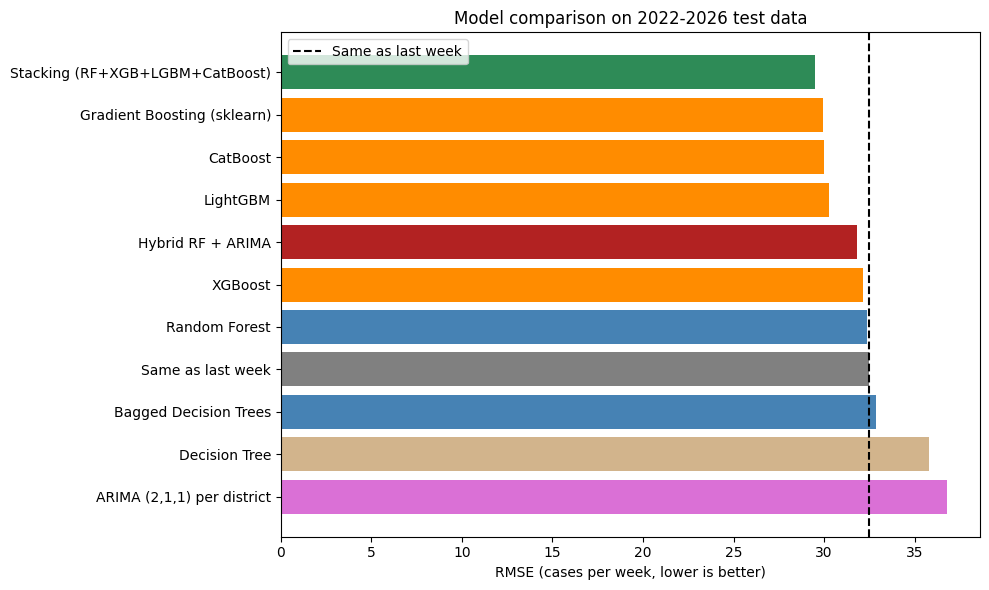

,Model,Type,RMSE,MAE,R2,Skill vs baseline,Outbreak-week MAE,Train time (s)
0,Stacking (RF+XGB+LGBM+CatBoost),Stacking,29.50,13.04,0.908,0.092,51.4,327.0
1,Gradient Boosting (sklearn),Boosting,29.94,13.10,0.905,0.079,51.7,51.3
2,CatBoost,Boosting,30.02,13.27,0.904,0.076,53.8,7.8
3,LightGBM,Boosting,30.27,13.14,0.903,0.069,51.9,2.8
4,Hybrid RF + ARIMA,Hybrid,31.79,13.55,0.893,0.022,55.5,97.2
5,XGBoost,Boosting,32.14,13.57,0.890,0.011,55.5,6.2
6,Random Forest,Bagging,32.36,13.36,0.889,0.004,55.0,78.4
7,Same as last week,Baseline,32.50,14.02,0.888,0.000,52.4,0.0
8,Bagged Decision Trees,Bagging,32.88,13.50,0.885,-0.012,54.9,53.8
9,Decision Tree,Single model,35.78,14.68,0.864,-0.101,62.1,0.4


In [ ]:
results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
colors = {"Baseline": "grey", "Single model": "tan", "Bagging": "steelblue", "Boosting": "darkorange",
          "Stacking": "seagreen", "Time series": "orchid", "Hybrid": "firebrick"}
plt.figure(figsize=(10, 6))
plt.barh(results_df["Model"], results_df["RMSE"], color=[colors[t] for t in results_df["Type"]])
plt.axvline(naive_rmse, color="black", linestyle="--", label="Same as last week")
plt.gca().invert_yaxis(); plt.xlabel("RMSE (cases per week, lower is better)")
plt.title("Model comparison on 2022-2026 test data"); plt.legend(); plt.tight_layout(); plt.show()
results_df

## Actual vs Predicted (Colombo)

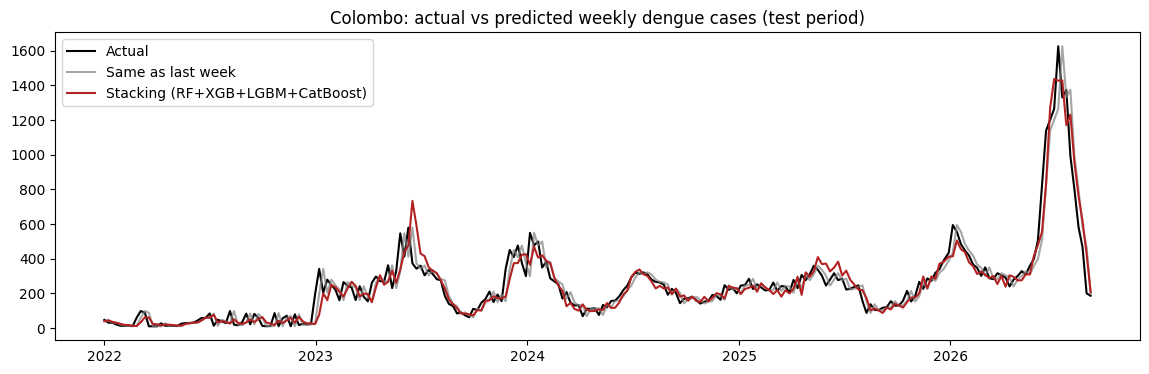

In [ ]:
best_name = results_df.loc[results_df["Type"] != "Baseline", "Model"].iloc[0]
mask = (test["district"] == "Colombo").values
plt.figure(figsize=(14, 4))
plt.plot(test.loc[mask, "start"], y_true[mask], label="Actual", color="black")
plt.plot(test.loc[mask, "start"], naive_pred[mask], label="Same as last week", color="grey", alpha=0.7)
plt.plot(test.loc[mask, "start"], predictions[best_name][mask], label=best_name, color="firebrick")
plt.title("Colombo: actual vs predicted weekly dengue cases (test period)"); plt.legend(); plt.show()

## Feature Importance

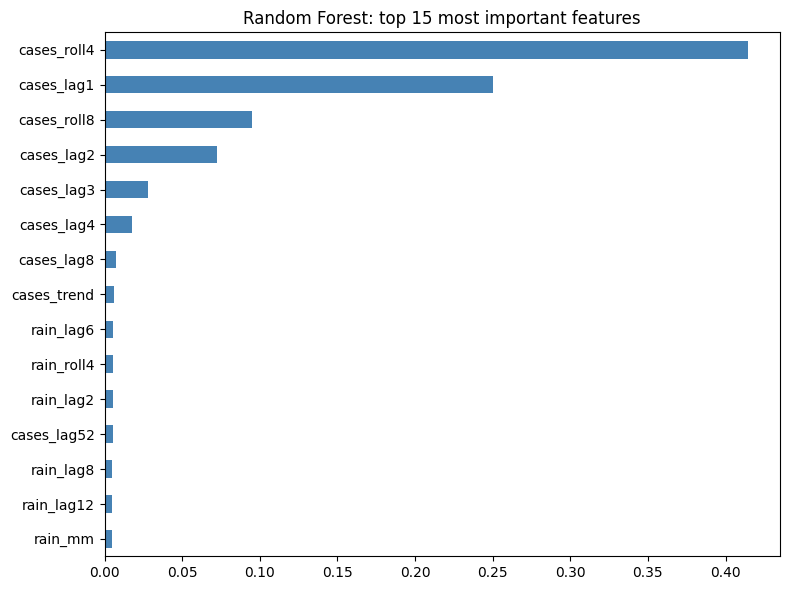

In [ ]:
imp = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False).head(15)
imp.sort_values().plot(kind="barh", figsize=(8, 6), color="steelblue")
plt.title("Random Forest: top 15 most important features"); plt.tight_layout(); plt.show()

## Results and Interpretation

**1. Best model:** Stacking performed best (RMSE 29.50, R² = 0.908), explaining about 91% of the variation in weekly cases and beating the "same as last week" baseline by 9.2%. Gradient Boosting, CatBoost and LightGBM were close behind (7–8% better than the baseline).

**2. Ensembles vs a single tree:** The single Decision Tree was 10% worse than the baseline because one tree is unstable (high variance). Random Forest averages 300 trees built on different samples, which cancels out individual errors and lowered the RMSE from 35.78 to 32.36.

**3. Boosting vs bagging:** All boosting models beat the baseline, while Random Forest only matched it. Bagging reduces variance by averaging, but this smooths predictions, so it reacts slowly when cases rise or fall. Boosting builds each tree to correct the previous trees' errors, which reduces bias and follows changes more closely.

**4. Stacking vs LightGBM for deployment:**  Stacking gave the lowest error (R² 0.908), but LightGBM was almost as accurate (R² 0.903, less than 1 case per week difference) and performed equally well in outbreak weeks. LightGBM is 67 times smaller (1.4 MB vs 94 MB), trains about 117 times faster (2.8 s vs 327 s) and depends on one library instead of four. When we tried deploying the stacking model, it failed to load on a different machine because of library version mismatches, while LightGBM loaded without issues. Since the small accuracy gain did not justify the extra size and fragility, LightGBM is used for the dashboard forecast.

**5. Hybrid RF + ARIMA:** ARIMA alone was the worst model (13% worse than the baseline) because it only uses each district's past cases. Adding a Random Forest to correct ARIMA's errors using weather, season and district reduced the error by 13.5% (36.77 → 31.79), beating Random Forest and XGBoost.

**6. Why the baseline is strong:** Consecutive weeks are highly correlated (about 0.93), so last week already explains most of next week. In outbreak weeks, only Stacking, Gradient Boosting and LightGBM beat the baseline; all models underestimate sudden peaks.

**7. Feature importance:** The 4-week average of cases (0.42) and last week's cases (0.25) dominate. Weather features are each only about 0.005, because past case counts already reflect the effect of earlier rainfall. Weather adds a small extra signal rather than driving the forecast.

**8. Data cleaning:** Repairing seven corrupted weeks (three scrambled, four duplicated) raised R² from about 0.79 to about 0.90, so data quality mattered more than the choice of model.

**9. Limitations:** delayed or corrupted case reports, one weather location per district, peaks underestimated and predicted about a week late, and limited hyperparameter tuning.

## Save Model and Results for the Dashboard

In [ ]:
import joblib, json, zipfile
os.makedirs("models", exist_ok=True)
os.makedirs("dashboard_data", exist_ok=True)

# 1. Deployed model: LightGBM
joblib.dump(lgbm, "models/lightgbm_model.pkl")
json.dump(feature_cols, open("models/feature_cols.json", "w"))

# 2. Comparison table, test predictions and feature importance
results_df.to_csv("dashboard_data/model_results.csv", index=False)
pred_out = test[["district", "start", "cases"]].copy()
for name, p in predictions.items():
    pred_out[name] = np.round(p, 1)
pred_out.to_csv("dashboard_data/test_predictions.csv", index=False)
pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False) \
  .rename("importance").to_csv("dashboard_data/feature_importance.csv")

# 3. Clean history for the data explorer page
data[["district", "year", "week", "start", "cases", "rain_mm", "temp_c", "humidity"]] \
  .to_csv("dashboard_data/history.csv", index=False)

# 4. Features for NEXT week, for the forecast page
last = data["start"].max()
future = data[data["start"] == last].copy()
future["start"] = last + pd.Timedelta(days=7)
future["cases"] = np.nan
future["week"] = future["start"].dt.isocalendar().week.astype(float).clip(upper=52)
full = pd.concat([data, future]).sort_values(["district", "start"]).reset_index(drop=True)
gf = full.groupby("district")
for k in [1, 2, 3, 4, 8, 52]:
    full[f"cases_lag{k}"] = gf["cases"].shift(k)
full["cases_roll4"] = gf["cases"].transform(lambda s: s.shift(1).rolling(4).mean())
full["cases_roll8"] = gf["cases"].transform(lambda s: s.shift(1).rolling(8).mean())
full["cases_trend"] = full["cases_lag1"] - full["cases_lag2"]
for k in [2, 4, 6, 8, 10, 12]:
    full[f"rain_lag{k}"]  = gf["rain_mm"].shift(k)
    full[f"temp_lag{k}"]  = gf["temp_c"].shift(k)
    full[f"humid_lag{k}"] = gf["humidity"].shift(k)
full["rain_roll4"] = gf["rain_mm"].transform(lambda s: s.shift(1).rolling(4).sum())
full["week_sin"] = np.sin(2 * np.pi * full["week"] / 52)
full["week_cos"] = np.cos(2 * np.pi * full["week"] / 52)
full = pd.concat([full, pd.get_dummies(full["district"], prefix="d", dtype=int)], axis=1)
next_week = full[full["start"] == last + pd.Timedelta(days=7)].copy()
next_week["forecast"] = np.round(np.clip(np.expm1(lgbm.predict(next_week[feature_cols])), 0, None), 0)
next_week[["district", "start", "cases_lag1", "forecast"] + feature_cols].to_csv("dashboard_data/next_week_features.csv", index=False)
print("Forecast for week starting", (last + pd.Timedelta(days=7)).date())
print(next_week[["district", "cases_lag1", "forecast"]].sort_values("forecast", ascending=False).head(10).to_string(index=False))

# 5. Zip everything for download
with zipfile.ZipFile("dashboard_files.zip", "w") as z:
    for folder in ["models", "dashboard_data"]:
        for f in os.listdir(folder):
            z.write(os.path.join(folder, f))
from google.colab import files
files.download("dashboard_files.zip")

Forecast for week starting 2026-09-07
   district  cases_lag1  forecast
    Colombo       186.0     189.0
    Gampaha        86.0      87.0
   Kalutara        78.0      84.0
      Galle        38.0      41.0
  Ratnapura        44.0      34.0
 Kurunegala        29.0      26.0
Hambanthota        21.0      25.0
     Matara        20.0      22.0
      Kandy         8.0      22.0
    Badulla        27.0      21.0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import lightgbm, sklearn, pandas, numpy
print("lightgbm==" + lightgbm.__version__)
print("scikit-learn==" + sklearn.__version__)
print("pandas==" + pandas.__version__)
print("numpy==" + numpy.__version__)

lightgbm==4.6.0
scikit-learn==1.6.1
pandas==2.2.3
numpy==2.4.6


In [ ]:
main_models = ["Same as last week", "Decision Tree", "Random Forest", "LightGBM",
               "Stacking (RF+XGB+LGBM+CatBoost)", "Hybrid RF + ARIMA"]
final_df = results_df[results_df["Model"].isin(main_models)].reset_index(drop=True)
final_df

,Model,Type,RMSE,MAE,R2,Skill vs baseline,Outbreak-week MAE,Train time (s)
0,Stacking (RF+XGB+LGBM+CatBoost),Stacking,29.50,13.04,0.908,0.092,51.4,327.0
1,LightGBM,Boosting,30.27,13.14,0.903,0.069,51.9,2.8
2,Hybrid RF + ARIMA,Hybrid,31.79,13.55,0.893,0.022,55.5,97.2
3,Random Forest,Bagging,32.36,13.36,0.889,0.004,55.0,78.4
4,Same as last week,Baseline,32.50,14.02,0.888,0.000,52.4,0.0
5,Decision Tree,Single model,35.78,14.68,0.864,-0.101,62.1,0.4


In [11]:
import xgboost, catboost; print(xgboost.__version__, catboost.__version__)

3.4.1 1.2.10
